# BALF EV proteomics — Figure 3 revision
**Reviewer #3, comment #4 | November 2026**

This notebook regenerates Figure 3 panels A–D from the recovered normalized BALF protein abundance matrix; it does not rerun upstream PSM processing. Run from the folder containing this notebook and `data/`. All paths are relative. The original notebooks and input CSVs are left unchanged. The two recovered matrices were reconstructed from `DG016210_PSMs (1).txt` using the historical BALF workflow. `Annotation (2).csv` is a historical complete-case abundance reference, not a full annotation table.

| Group | Exposure | Activity | Samples |
|---|---|---|---:|
| 1 | Air | Rest | 6 |
| 2 | Air | Exercise | 9 |
| 3 | Cigarette smoke (CS) | Rest | 7 |
| 4 | Cigarette smoke (CS) | Exercise | 8 |

No protein-level imputation or log transformation before the Welch tests. Fold change = arithmetic mean of the first-named group / arithmetic mean of the second. Signed π = log₂(fold change) × −log₁₀(raw p). Volcano colors use nominal p < 0.05 and |log₂ fold change| ≥ 0.5; π selection uses |π| > 1.0. These are exploratory criteria, not multiplicity-adjusted significance. BH and Bonferroni columns are provided for reference only. The four archived π-score lists validate protein identities and statistics and supply historical labels. Missing or ambiguous annotations are not inferred; accession IDs are used as fallbacks.

New presentation choices: lighter blue (higher), orange (lower), grey (other), common axes, at most four lowest-p labels per direction, offset labels with leader lines. Original pathway panels E–G are not modified. This is a proposed visual revision, not the final assembled manuscript figure.

## 1. Imports and figure configuration

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
from scipy.stats import ttest_ind
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.transforms import Bbox

ROOT=Path.cwd()
DATA=ROOT/'data'; FIG=ROOT/'figures'; RESULTS=ROOT/'results'
FIG.mkdir(exist_ok=True); RESULTS.mkdir(exist_ok=True)
N_LABELS=4
FC_THRESHOLD=.5
P_THRESHOLD=.05
PI_THRESHOLD=1.0
COLORS={'Lower':'#D98949','Other':'#B6B6B6','Higher':'#62A6D5'}
COMPARISONS=[('A',2,1,'Air + Ex vs. Air + Rest'),('B',3,1,'CS + Rest vs. Air + Rest'),('C',4,3,'CS + Ex vs. CS + Rest'),('D',4,2,'CS + Ex vs. Air + Ex')]
plt.rcParams.update({'font.family':'DejaVu Sans','font.size':8,'axes.spines.top':False,'axes.spines.right':False,'axes.labelsize':9,'xtick.labelsize':8,'ytick.labelsize':8,'pdf.fonttype':42,'svg.fonttype':'none','savefig.facecolor':'white'})

In [10]:
# Set global figure resolution
import matplotlib.pyplot as plt
from matplotlib_inline.backend_inline import set_matplotlib_formats

plt.rcParams.update({
    'figure.dpi': 300,
    'savefig.dpi': 600
})

set_matplotlib_formats('png')

## 2. Validate recovered input data and sample map

In [11]:
# Verify the two input matrices and the independently archived complete-case data.
mouse_matrix = pd.read_csv(DATA / 'BALF_Normalized_reconstructed.csv').set_index('Master Protein')
group_matrix = pd.read_csv(DATA / 'BALF_Normalized_named_reconstructed.csv').set_index('Master Protein')
sample_map = pd.read_csv(DATA / 'sample_map.csv', dtype={'mouse_id': str})
assert mouse_matrix.index.equals(group_matrix.index)
assert list(mouse_matrix.columns) == sample_map['mouse_id'].tolist()
assert list(group_matrix.columns) == sample_map['matrix_column'].tolist()
np.testing.assert_allclose(mouse_matrix.to_numpy(), group_matrix.to_numpy(), rtol=1e-12, atol=1e-12, equal_nan=True)
assert sample_map.groupby('group').size().to_dict() == {1: 6, 2: 9, 3: 7, 4: 8}
reference = pd.read_csv(DATA / 'Annotation (2).csv').set_index('Master Protein')
assert set(reference.index) == set(mouse_matrix.dropna().index)
np.testing.assert_allclose(mouse_matrix.loc[reference.index, reference.columns], reference, rtol=1e-8, atol=1e-10)
print(f'{len(mouse_matrix):,} proteins × {mouse_matrix.shape[1]} samples; {len(reference)} complete reference proteins verified.')
print(f'Missing protein-level abundances retained: {mouse_matrix.isna().sum().sum():,}')
print('Both matrix versions and all sample assignments agree.')

1,116 proteins × 30 samples; 704 complete reference proteins verified.
Missing protein-level abundances retained: 6,180
Both matrix versions and all sample assignments agree.


## 3. Reproduce and validate the original statistics

In [12]:
# Recovered original matrix; no imputation or transformation before Welch tests.
mat=pd.read_csv(DATA/'BALF_Normalized_named_reconstructed.csv').set_index('Master Protein')
assert mat.index.is_unique and mat.shape==(1116,30)
legacy={panel:pd.read_csv(DATA/f'grp{a}{b}pi (2).csv').set_index('Master Protein') for panel,a,b,_ in COMPARISONS}
ann=pd.concat([t['Proteins'] for t in legacy.values()]); assert ann.groupby(level=0).nunique().max()==1
ann=ann[~ann.index.duplicated()].astype(str)
# Some original names are placeholders (e.g. 1); accession is a stable fallback.
ann=ann.where(~ann.str.fullmatch(r'\d+|nan|None',case=False))

def bh(p):
    p=np.asarray(p); out=np.full(p.shape,np.nan); ok=np.isfinite(p); vals=p[ok]; order=np.argsort(vals); ranks=np.arange(1,len(vals)+1)
    q=np.minimum.accumulate((vals[order]*len(vals)/ranks)[::-1])[::-1].clip(0,1); tmp=np.empty_like(vals); tmp[order]=q; out[ok]=tmp; return out

def compare(panel,a,b):
    x=mat.filter(regex=rf'^Grp{a}(\.|$)'); y=mat.filter(regex=rf'^Grp{b}(\.|$)')
    t=pd.DataFrame(index=mat.index)
    t['Protein label']=ann.reindex(t.index)
    t['Display label']=t['Protein label'].fillna(pd.Series(t.index,index=t.index))
    t['n numerator']=x.count(axis=1); t['n denominator']=y.count(axis=1)
    t['mean numerator']=x.mean(axis=1); t['mean denominator']=y.mean(axis=1)
    t['fold change']=t['mean numerator']/t['mean denominator']
    t['log2 fold change']=np.log2(t['fold change'])
    t['raw p']=ttest_ind(x.to_numpy(),y.to_numpy(),axis=1,equal_var=False,nan_policy='omit').pvalue
    t['minus log10 p']=-np.log10(t['raw p']); t['pi score']=t['log2 fold change']*t['minus log10 p']
    t['BH q (reference only)']=bh(t['raw p']); t['Bonferroni p (reference only)']=(t['raw p']*t['raw p'].notna().sum()).clip(upper=1)
    t['pi selected']=t['pi score'].abs()>PI_THRESHOLD
    t['category']='Other'
    t.loc[(t['raw p']<P_THRESHOLD)&(t['log2 fold change']>=FC_THRESHOLD),'category']='Higher'
    t.loc[(t['raw p']<P_THRESHOLD)&(t['log2 fold change']<=-FC_THRESHOLD),'category']='Lower'
    old=legacy[panel]
    assert set(t.index[t['pi selected']])==set(old.index)
    for col,original in [('raw p','ttest_pvalue'),('log2 fold change','Log2(Fold Change)'),('pi score',f'Grp{a}/Grp{b} pi score')]:
        np.testing.assert_allclose(t.loc[old.index,col],old[original],rtol=1e-6,atol=1e-8)
    t['labeled']=False
    for cat in ['Higher','Lower']:
        ids=t[t.category==cat].sort_values('raw p',kind='stable').head(N_LABELS).index
        t.loc[ids,'labeled']=True
    t.to_csv(RESULTS/f'{panel}_Grp{a}_vs_Grp{b}_all_proteins.csv')
    return t

stats={p:compare(p,a,b) for p,a,b,_ in COMPARISONS}
for p,t in stats.items():
    print(p, 'tested',t['raw p'].notna().sum(),'volcano',t.category.ne('Other').sum(),'pi',t['pi selected'].sum(),'labels',t.labeled.sum())
summary = pd.DataFrame([{'panel':p, 'comparison':title, 'tested':int(stats[p]['raw p'].notna().sum()), 'volcano_higher':int(stats[p].category.eq('Higher').sum()), 'volcano_lower':int(stats[p].category.eq('Lower').sum()), 'pi_selected':int(stats[p]['pi selected'].sum()), 'BH_q_below_0.05':int(stats[p]['BH q (reference only)'].lt(.05).sum()), 'labels':int(stats[p].labeled.sum())} for p,a,b,title in COMPARISONS])
summary.to_csv(RESULTS / 'comparison_summary.csv', index=False)
summary

A tested 1116 volcano 23 pi 38 labels 8
B tested 1116 volcano 251 pi 267 labels 8
C tested 1116 volcano 16 pi 11 labels 8
D tested 1116 volcano 175 pi 195 labels 8


,panel,comparison,tested,volcano_higher,volcano_lower,pi_selected,BH_q_below_0.05,labels
0,A,Air + Ex vs. Air + Rest,1116,11,12,38,0,8
1,B,CS + Rest vs. Air + Rest,1116,124,127,267,118,8
2,C,CS + Ex vs. CS + Rest,1116,10,6,11,0,8
3,D,CS + Ex vs. Air + Ex,1116,97,78,195,184,8


## 4. Set common axes and plotting thresholds

In [13]:
# Fixed scales across panels for direct visual comparison.
XMAX=3.8; YMAX=7.75
# Guard against accidentally clipping any valid data point.
for panel, t in stats.items():
    assert np.isfinite(t[['log2 fold change','minus log10 p']]).all().all(), panel
    assert t['log2 fold change'].abs().max() <= XMAX, panel
    assert t['minus log10 p'].between(0, YMAX).all(), panel

def base_plot(ax,p,title,t):
    for cat in ['Other','Lower','Higher']:
        sub=t[t.category==cat]
        ax.scatter(sub['log2 fold change'],sub['minus log10 p'],s=7 if cat=='Other' else 13,c=COLORS[cat],alpha=.65 if cat=='Other' else .90,linewidths=0,zorder=2 if cat=='Other' else 3)
    for val in [-FC_THRESHOLD,FC_THRESHOLD]: ax.axvline(val,color='#858585',lw=.65,ls=(0,(3,3)),zorder=1)
    ax.axhline(-np.log10(P_THRESHOLD),color='#858585',lw=.65,ls=(0,(3,3)),zorder=1)
    ax.set(xlim=(-XMAX,XMAX),ylim=(0,YMAX),xticks=[-3,-2,-1,0,1,2,3],yticks=range(0,8,2),xlabel=r'$\log_2$(fold change)',ylabel=r'$-\log_{10}$(raw $p$)')
    ax.set_title(title,fontsize=10,pad=9,fontweight='medium')
    ax.text(-.15,1.045,p,transform=ax.transAxes,fontsize=13,fontweight='bold',va='bottom')
    ax.spines[['bottom','left']].set_color('#555555'); ax.tick_params(length=3,width=.7,color='#555555')

## 5. Place labels without collisions

In [24]:
# Deterministic annotation placement: choose offsets in display coordinates,
# penalize overlap with other labels, plot boundaries, and data points.
# Labels are black with a narrow white backing and unobtrusive leader lines.
def annotate(ax,t):
    fig=ax.figure; fig.canvas.draw(); renderer=fig.canvas.get_renderer(); bounds=ax.get_window_extent(); occupied=[]
    pts=ax.transData.transform(t[['log2 fold change','minus log10 p']].to_numpy()); factor=fig.dpi/72
    for idx,r in t[t.labeled].sort_values('raw p').iterrows():
        xy=(r['log2 fold change'],r['minus log10 p']); anchor=ax.transData.transform(xy)
        probe=ax.text(0,0,r['Display label'],fontsize=7.5,alpha=0); b=probe.get_window_extent(renderer); probe.remove(); w,h=b.width,b.height
        sign=1 if xy[0]>0 else -1
        candidates=[]
        for dx in [9,17,26,36,48,62,78]:
            for dy in [5,-5,15,-15,25,-25,38,-38,52,-52,67,-67]:
                for side in [sign,-sign]:
                    sx=side*dx; x=anchor[0]+sx*factor; y=anchor[1]+dy*factor; left=x if side==1 else x-w
                    box=Bbox.from_extents(left-2,y-h/2-2,left+w+2,y+h/2+2)
                    if box.x0<bounds.x0+2 or box.x1>bounds.x1-2 or box.y0<bounds.y0+2 or box.y1>bounds.y1-2: continue
                    overlap=sum(box.overlaps(o) for o in occupied)
                    # Protective buffer around protein dots (in typographic points)
                    buffer = 4 * factor

                    count = np.sum(
                        (pts[:, 0] > box.x0 - buffer) &
                        (pts[:, 0] < box.x1 + buffer) &
                        (pts[:, 1] > box.y0 - buffer) &
                        (pts[:, 1] < box.y1 + buffer)
                    )
                    cost=10000*overlap+3000*count+np.hypot(dx,dy)+8*(side!=sign)
                    candidates.append((cost,sx,dy,side,box))
        if not candidates: raise RuntimeError(f'No label position for {idx}')
        _,dx,dy,side,box=min(candidates,key=lambda c:c[0]); occupied.append(box)
        ax.annotate(r['Display label'],xy=xy,xytext=(dx,dy),textcoords='offset points',ha='left' if side==1 else 'right',va='center',fontsize=7.5,color='#171717',bbox=dict(boxstyle='square,pad=.12',fc='white',ec='none',alpha=.94),arrowprops=dict(arrowstyle='-',color='#686868',lw=.6,shrinkA=1,shrinkB=2),zorder=5)
        ax.scatter(*xy,s=20,facecolor=COLORS[r.category],edgecolor='#343434',linewidth=.45,zorder=4)

## 6. Export all panels

In [25]:
legend=[Line2D([],[],marker='o',ls='',color=COLORS[c],markersize=5,label=l) for c,l in [('Lower','Lower abundance'),('Other','Below either cutoff'),('Higher','Higher abundance')]]

def save(fig,stem):
    for ext in ['png','pdf','svg']:
        fig.savefig(FIG/f'{stem}.{ext}',dpi=600)

fig,axs=plt.subplots(2,2,figsize=(8.4,7.5)); fig.subplots_adjust(left=.085,right=.975,bottom=.165,top=.935,wspace=.34,hspace=.37)
for ax,(p,a,b,title) in zip(axs.flat,COMPARISONS): base_plot(ax,p,title,stats[p])
for ax,(p,a,b,title) in zip(axs.flat,COMPARISONS): annotate(ax,stats[p])
fig.legend(handles=legend,loc='lower center',bbox_to_anchor=(.5,.065),ncol=3,frameon=False,fontsize=8.5)
fig.text(.5,.025,'Cutoffs: |log₂ fold change| ≥ 0.5 and raw p < 0.05 (unadjusted).',ha='center',fontsize=8)
save(fig,'Figure3_ABCD_volcano'); fig.savefig(FIG/'Figure3_preview.png',dpi=160); plt.close(fig)
for p,a,b,title in COMPARISONS:
    fig,ax=plt.subplots(figsize=(4.25,3.85)); fig.subplots_adjust(left=.16,right=.95,bottom=.23,top=.86)
    base_plot(ax,p,title,stats[p]); annotate(ax,stats[p]); fig.legend(handles=legend,loc='lower center',bbox_to_anchor=(.5,.045),ncol=3,frameon=False,fontsize=7)
    save(fig,f'Figure3_{p}_Grp{a}_vs_Grp{b}'); plt.close(fig)

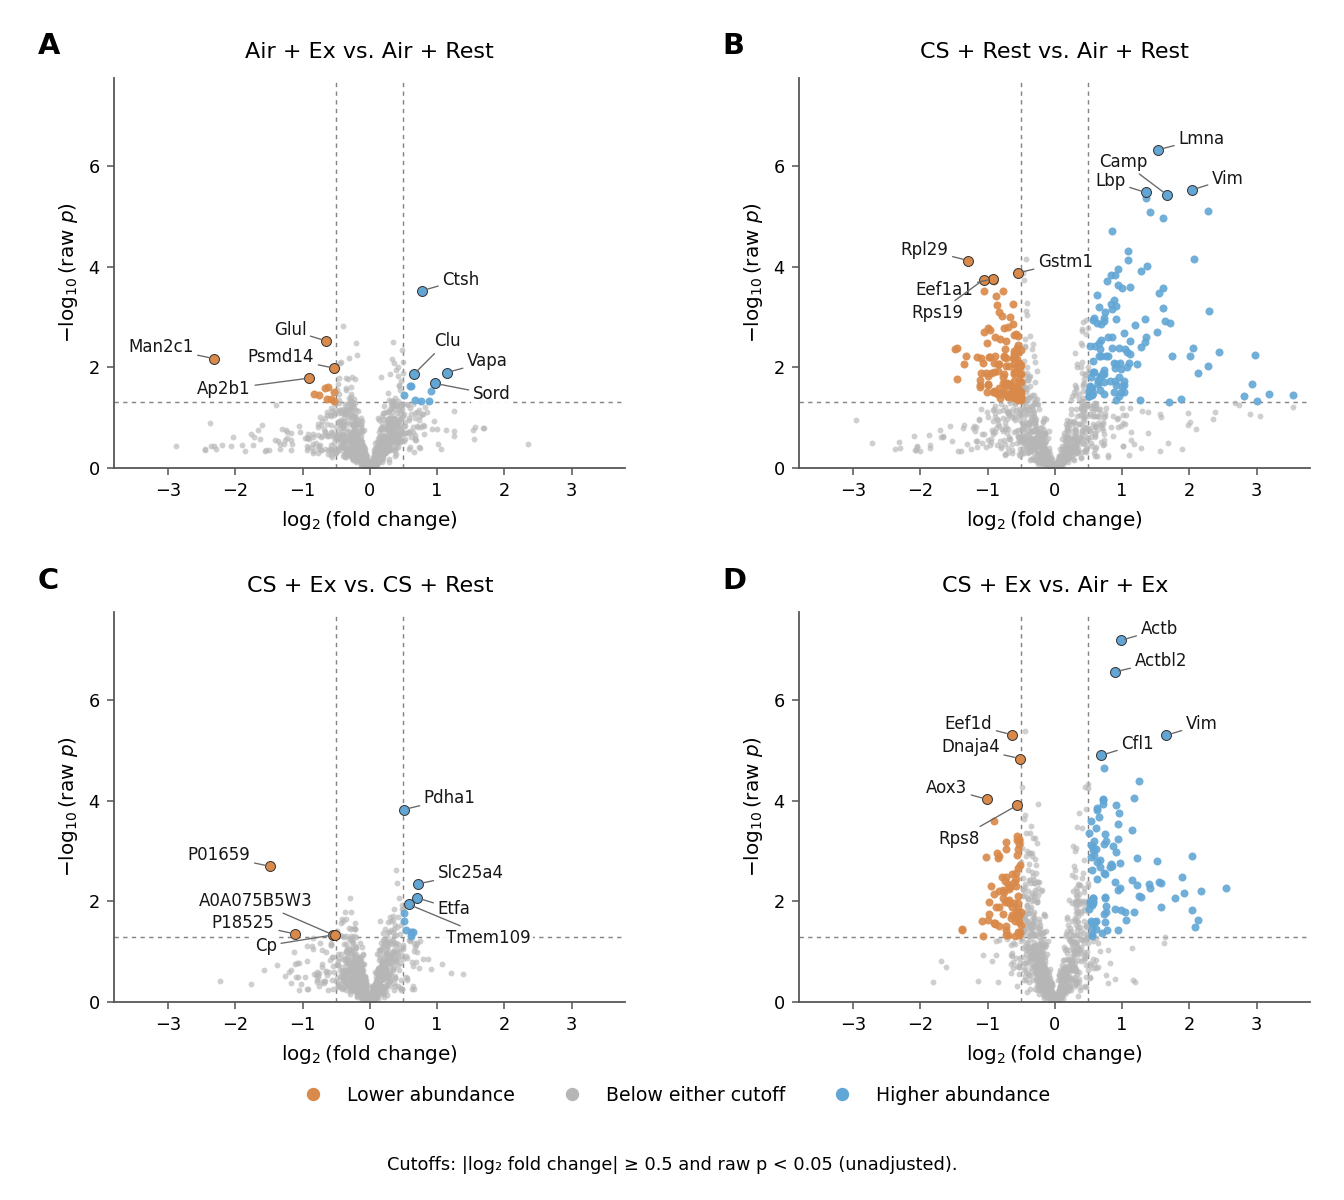

In [26]:
from IPython.display import Image, display
display(Image(filename=str(FIG / 'Figure3_preview.png')))